<style>
    #top {
        display: grid;
        grid-template-columns: auto auto auto
    }

    #top a {
        padding: 10px;
        background-color: blue;
        color: white;
        text-decoration: none
    }

    #top a:first-child {
        justify-self: start
    }

    #top a:last-child {
        justify-self: end
    }

    #top a:hover {
        background-color: darkblue;
    }
</style>

<div id="top">
    <a href="../notebook/1_initial-data-analysis.ipynb">Previous</a>
    <h2 style="margin: 0; text-align: center;">Section 2 | Exploratory Data Analysis</h2>
    <a href="../notebook/3_predictive-modeling.ipynb">Next</a>
</div>

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import patsy
import seaborn as sns
import statsmodels.api as sm
from dython.nominal import associations
from notebook_helpers import (
    SEED,
    DropValues,
    data_cleaned_etl,
    inspect_dimensionality,
    random_number_generator,
)
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor


### Train-Test Split

*The train-test split is a technique for evaluating the performance of a machine learning algorithm. The procedure involves taking a dataset and dividing it into two subsets:*
1. *The training dataset is used to learn the model parameters and is the focus of the analysis in this section, while*
2. *The test dataset is used to evaluate the model's performance on unseen data and to ensure that it generalizes well to new examples.*

In [2]:
# set random number generator instance
rng = random_number_generator(SEED)

*Some scikit-learn `sklearn` objects are [inherently random](https://scikit-learn.org/stable/common_pitfalls.html#controlling-randomness). The randomness of these objects is controlled via their `random_state` parameter.*
* *In order to obtain reproducible (i.e. constant) results across multiple executions of this project, the recommended way is to declare an `rng` variable at the top of the project, and pass it down to any object that accepts a `random_state` parameter.*
* *The random seed used arbitrarily throughout this project is [42](https://en.wikipedia.org/wiki/42_(number)).*

In [3]:
# split dataset to random train and test subsets
data_cleaned = data_cleaned_etl()
train, test = train_test_split(data_cleaned, random_state=rng)
data_train, data_test = pd.DataFrame(train), pd.DataFrame(test)

# perform dimensionality analysis on dataset and its subsets
inspect_dimensionality(data_cleaned, data_train, data_test)

,row_n,row_ratio,column
dataset,392,1.00,8
train,294,0.75,8
test,98,0.25,8


The table above describes the dimensionality of the Auto MPG dataset after the data were split into train and test subsets:
* The complete dataset consists of `392` rows and `8` columns.
* `train_test_split` divides the data into a pair of `data_train` and `data_test` sets.
    * The number of rows in the dataset is split into approximately `0.75/75%` for the training set and `0.25/25%` for the test set, matching the default parameters.
    * This split only divides the rows/observations, so the number of columns/variables remains unchanged.

### Univariate EDA

*Univariate analysis is the simplest form of data analysis, focusing on describing and summarizing a single variable at a time. It analyzes the distribution, central tendency (mean, median, mode), and dispersion (range, variance) to identify patterns, outliers, and data characteristics, rather than examining relationships between variables.*

#### Descriptive Statistics

In [4]:
# subset numerical variables from train set
numerical_train = data_train.select_dtypes("number")

# generate simple descriptive statistics for numerical variables
percentiles = [0.5]
decimals = 2
numerical_train.describe(percentiles).round(decimals)

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
count,294.00,294.00,294.00,294.00,294.00,294.00,294.00,294.00
mean,195.48,5.47,104.47,2971.83,15.51,76.14,1.57,23.69
std,104.66,1.71,38.60,841.77,2.86,3.65,0.82,8.01
min,70.00,3.00,46.00,1613.00,8.00,70.00,1.00,9.00
50%,151.00,4.00,92.50,2781.50,15.40,76.00,1.00,23.00
max,455.00,8.00,230.00,5140.00,24.80,82.00,3.00,46.60


*The exact numerical statistics for `numerical_variables` are provided above in tabular format.*
* *`count` refers to the number of non-null values for each column (similar to the `Row/Instance` values in [Section 1: Data Inspection](#data-inspection)),*
* *`mean` measures the [average](https://en.wikipedia.org/wiki/Arithmetic_mean) of the values in each column,*
* *`std` represents the [standard deviation](https://en.wikipedia.org/wiki/Standard_deviation) for each variable,*
* *`min` and `max` are the minimum and maximum of the values in each column, respectively, and*
* *`50%` is the corresponding [percentile](https://en.wikipedia.org/wiki/Percentile)—also known as the [median](https://en.wikipedia.org/wiki/Median).*

A difference in the value range or [**order of magnitude**](https://en.wikipedia.org/wiki/Order_of_magnitude) is detected across the numerical variables:
* The range begins at `8.00` for the `acceleration` variable and extends to `5140.00` for the `weight` variable.
* This variation may pose several problems in machine learning:
    * In linear regression models, the scale of variables used to estimate the output matters. Linear models take the form $y = wx + b$, where the regression coefficient $w$ represents the expected change in $y$ for a one-unit change in $x$ (the predictor).
    * Thus, the magnitude of $w$ is partly determined by the magnitude of the units used for $x$. If $x$ is a mass variable, changing the scale from pounds to grams will change the magnitude of the coefficient.
* In addition, the numerical values in the Auto MPG training set all fall in a positive range (> 0).

#### Visual Analysis

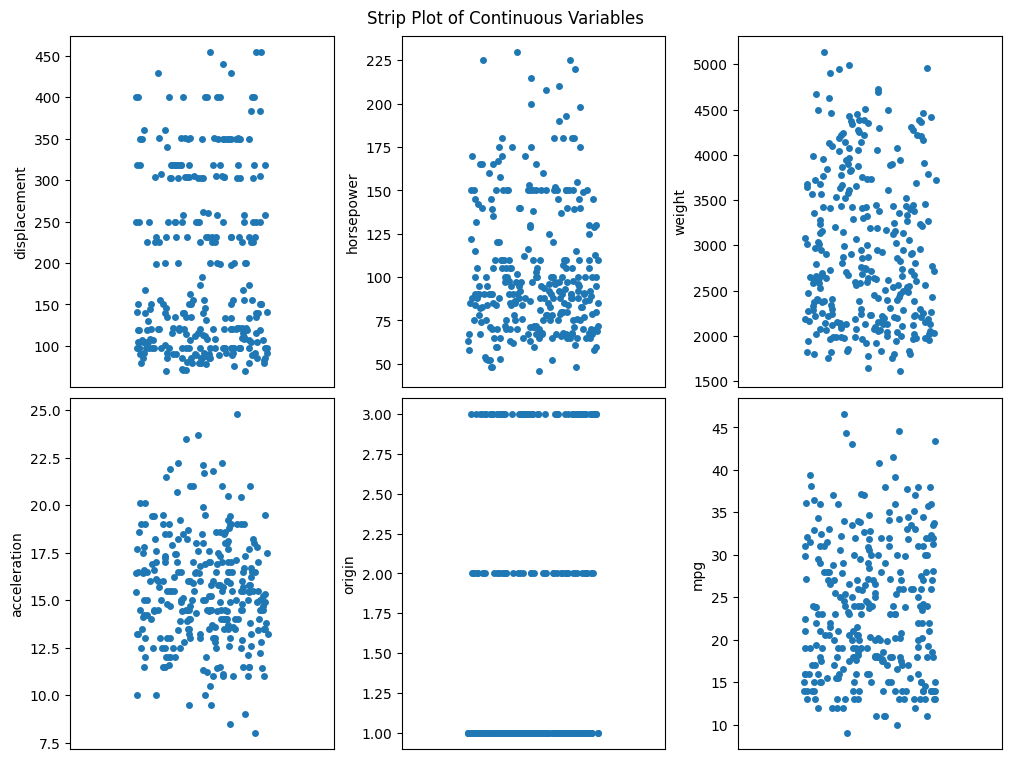

In [5]:
# setup plot figure for continuous variables visualization
width, height = 10, 7.5
plt.figure(figsize=(width, height), layout="constrained")
plt.suptitle("Strip Plot of Continuous Variables")

# subset variables with continuous data type from numerical variables
discrete_columns = ["cylinders", "model_year"]
continuous_train = numerical_train.drop(columns=discrete_columns)

# plot visualization for continuous variables
start_enumerate = 1
nrows, ncols = 2, 3
jitter = 0.25
for count, column in enumerate(continuous_train, start_enumerate):
    plt.subplot(nrows, ncols, count)
    sns.stripplot(continuous_train, y=column, jitter=jitter)
    plt.xticks([])

*[Strip plot](https://seaborn.pydata.org/tutorial/categorical.html#categorical-tutorial) is used to show data points across the continuous numerical variables in the Auto MPG dataset.*
* *Each dot represents an observation of a car sample in the Auto MPG dataset.*
* *Because the number of observations is in the hundreds and relatively high, a `jitter` value is applied to display the data points as non-overlapping as possible.*

Several insights can be drawn from this simple visualization, such as the data spread, skewness, and distribution gaps. However, the focus of this analysis is to detect the presence of [outliers](https://en.wikipedia.org/wiki/Outlier) in each variable:
* One can see clusters of data points, such as in the `displacement & horsepower` variables, indicating [modality](https://en.wikipedia.org/wiki/Mode_(statistics)) of continuous values within the range along the $y$-axis that forms these clusters.
* For example, in the `horsepower` variable, there are data points at the upper extremity of the plot representing the value `max (230)` for that variable, which was found earlier and lies relatively far from the mode of the variable.
* It is important to note that this extreme value is not far from the surrounding data points and is not an error as discussed in [Initial Data Inspection](#initial-data-inspection), so it can be defined as a *non-outlier*.

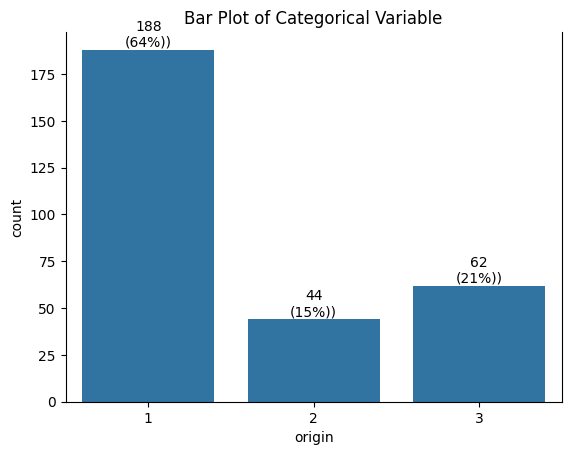

In [6]:
# plot visualization for categorical variables
categorical_column = ["origin"]
multiply_percent = 100
columns = 1
data_barplot = pd.concat([
    data_train[categorical_column].value_counts().sort_index(),
    data_train[categorical_column].value_counts(normalize=True).mul(multiply_percent)
], axis=columns)
axes = sns.barplot(data_barplot.reset_index(), x="origin", y="count")

proportion_index, barplot_index = 1, 0
labels = [
    f"{round(value.get_height())}\n({round(data_barplot.iloc[index, proportion_index])}%))"
    for index, value in enumerate(axes.containers[barplot_index])
]
axes.bar_label(axes.containers[barplot_index], labels=labels)
axes.spines.top.set_visible(False)

plt.title("Bar Plot of Categorical Variable")
plt.show()

*[Bar chart](https://en.wikipedia.org/wiki/Bar_chart) is a chart that presents categorical data with rectangular bars whose heights or lengths are proportional to the values they represent.*
* *One axis of the chart shows the specific categories being compared, and the other axis represents a measured value.*
* *Categorical variables are those whose values are selected from a group of categories—also called labels.*
* *Each chart in the plot above represents the labels in a particular variable and the occurrences (count) of each label.*
* *For example, in the `origin` variable, the label with the highest occurrence is `1`, with `183` observations or `62%` of the entire dataset.*

Based on this visualization, no particular issue is detected with the only categorical feature in the Auto MPG dataset.
* The `origin` variable contains only 3 labels, which is a relatively small number of categories.
* Although label `1` dominates this variable with `64%` of the frequency, labels `2` and `3` are also quite common, covering `15%` and `21%` of the data, respectively.

### Multivariate EDA

*[Multivariate analysis](https://en.wikipedia.org/wiki/Multivariate_statistics) encompasses the simultaneous observation and analysis of more than one variables, in order to understand the relationships between them and their relevance to the problem being studied. It may also determine to what extent it becomes easier to know and predict a value for one variable (possibly a dependent variable) if the value of the other variable (possibly the independent variable) is known.*

#### Discrete-Dependent Relationship

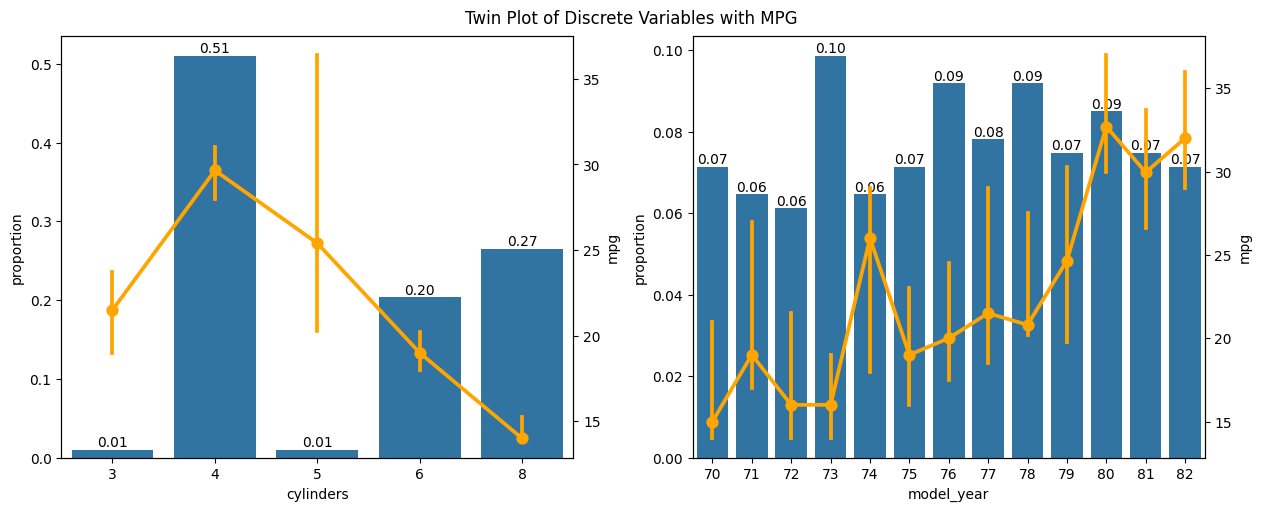

In [7]:
# setup plot figure for discrete variables visualization
width, height = 12.5, 5
plt.figure(figsize=(width, height), layout="constrained")
plt.suptitle("Twin Plot of Discrete Variables with MPG")

# subset variables with discrete data type from numerical variables
dependent_column = "mpg"
continuous_columns = continuous_train.drop(columns=dependent_column).columns.tolist()
discrete_dependent_train = numerical_train.drop(columns=continuous_columns)

# plot visualization for discrete variables
nrows, ncols = 1, 2
for count, column in enumerate(discrete_dependent_train, start=start_enumerate):
    if column != dependent_column:
        plt.subplot(nrows, ncols, count)
        kwargs = {"data": discrete_dependent_train, "x": column}

        axes = sns.countplot(**kwargs, stat="proportion")
        axes.bar_label(axes.containers[0], fmt='%.2f')

        axes_twinx = axes.twinx()
        sns.pointplot(
            **kwargs,
            y=dependent_column,
            estimator="median",
            errorbar="ci",
            seed=rng,
            color="orange",
            ax=axes_twinx,
        )

The visualization above consists of 2 components:
1. [Count plot](https://seaborn.pydata.org/generated/seaborn.countplot.html) shows the counts of observations for each discrete value using bars.
    * Instead of counts, `proportion` is used to show the percentages of labels in `cylinders` and `model_year`.
    * The proportion of labels in `model_year` is comparable—ranging from `0.06` or 6% up to 10%.
    * The same cannot be said for `cylinders`: city-cycles with `4` cylinders represent 51% of the whole Auto MPG dataset, while `3 & 5` are **rarely observed**, with only 1% for each of them.
2. [Point plot](https://seaborn.pydata.org/generated/seaborn.pointplot.html) represents an estimate of central tendency for the discrete numerical variables by the position of the dot and provides some indication of the uncertainty around that estimate using [error bars](https://seaborn.pydata.org/tutorial/error_bars.html).
    * *The central tendencies for both variables are also defined according to insights found in [Section 2: Statistical Analysis](#statistical-analysis).*
    * *The confidence interval `ci` is implemented to show the range of likely values for the true population parameter (`median`) over random samples in Auto MPG.*
    * Median MPG shows an overall upward trend in `model_year`, although not perfectly linear. Subsequent analysis performed to check whether a similar pattern occurs in other variables.
    * On the contrary, the median generally decreases as cylinder count increases from `4-8`. The exception is for `3 & 5` cylinders: these cars have a very small sample size, resulting in unstable estimates (wider `mpg` interval).

For values that are over-represented in the dataset, they tend to dominate the outcome. More specifically:
* A number of infrequent values adds noise with little information and therefore causes overfitting.
    * Replacing those labels with either the most frequent value or merging rare values together may be done. However, ideally, the distribution of values within the rare and frequent categories should be evaluated beforehand.
    * Although the proportions of the `3 & 5` values are similar, a significant difference can be seen in the `mpg` interval range for these two values, especially when compared with the frequent value of `4` cylinders.
* Rare values may be present in the training set but not in the test set, which also causes overfitting to the training set.
    * Conversely, rare values may only appear in the test set, so the machine learning model will not know how to evaluate them.

***Addendum: Rare Values Treatment***

To address the issue of noisy rare values of `3 & 5` in the `cylinders` variable, the custom `DropValues` transformer class is used, and those rare values are excluded from the modeling stage that follows.

In [8]:
# discard rare values from "cylinders" column in dataset
rare_column, rare_values = "cylinders", [3, 5]
dropper = DropValues(rare_column, rare_values)
data_model = pd.DataFrame(dropper.fit_transform(data_cleaned))

rare_counts = data_model[rare_column].value_counts()
pd.DataFrame(rare_counts)

,count
cylinders,
4,199
8,103
6,83


* The table above shows the unique labels and counts in `cylinders` after removing the rare values from the variable.
* Another train-test split is then performed to prepare the dataset for feature engineering.

In [9]:
# repeat split after discarding rare values
data_train, data_test = train_test_split(data_model, random_state=rng)

#### Correlation Analysis

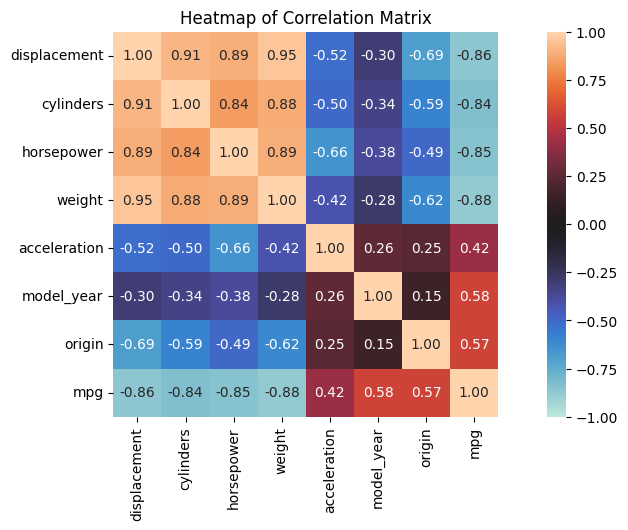

In [10]:
# calculate & visualize correlation of variables
associations_result = associations(
    data_train,
    num_num_assoc="spearman",
    nom_num_assoc="correlation_ratio",
    figsize=(width, height),
    title="Heatmap of Correlation Matrix"
)

associations_result["ax"]
plt.show()

*The heatmap above is a visualization of the pairwise [correlation matrix](https://en.wikipedia.org/wiki/Correlation#Correlation_matrices) between features in `data_train`, using:*
* *[Spearman's R](https://en.wikipedia.org/wiki/Spearman's_rank_correlation_coefficient) to measure monotonicity between numerical variables, and*
* *[Correlation ratio](https://en.wikipedia.org/wiki/Correlation_ratio) to assess the linear/curvilinear relationship between nominal (categorical) and numerical variables.*

In general, the key point here is the cluster of near-perfect positive coefficients in the upper left of the plot, from `displacement` to `weight` across both axes.
* This means that all data points with larger $x$-axis values than a given point will also tend to have larger $y$-axis values, and vice versa.
* Additional information is provided through the [Variance Inflation Factor](#linear-model-assumption) analysis below to assess correlations beyond pairwise relationships (multivariate).

#### Linear Model Assumptions

In [11]:
# setup design matrices for statsmodels
formula = "mpg ~ displacement + cylinders + horsepower + weight + acceleration + model_year + C(origin)" # treat "origin" explicitly as categorical
endog, exog = patsy.dmatrices(formula, data_train, return_type="dataframe")

# fit ordinary least squares (OLS) model
model = sm.OLS(endog, exog)
results = model.fit()

# access attributes from fitting results
y_pred = results.fittedvalues
resid = results.resid
influence = results.get_influence()
resid_norm = influence.resid_studentized_internal
resid_norm_abs_sqrt = np.sqrt(np.abs(resid_norm))
leverage = influence.hat_matrix_diag

*A linear model serves as one of the simplest, most interpretable, and strongest baseline methods for statistical learning (James, 2023, pp. 23-5).*
* *Although in reality the relationships between variables are often not linear, fitting a linear regression to a nonlinear relationship in this case may be problematic.*
* *The following section uses the output from `statsmodels` to visualize and identify potential problems that may arise from fitting a linear model to the dataset when doing so violates the [assumptions of linear regression](https://en.wikipedia.org/wiki/Ordinary_least_squares#Assumptions).*

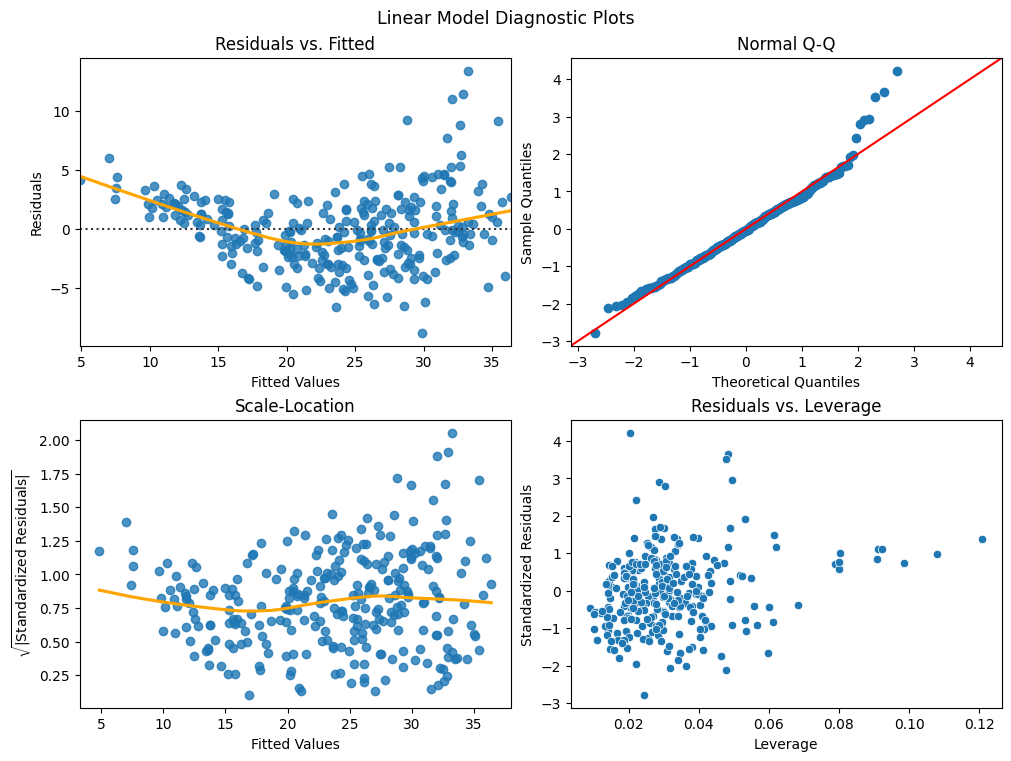

In [12]:
# visualize diagnostics for linear model assumptions
width, height = 10, 7.5
fig = plt.figure(figsize=(width, height), layout="constrained")
mosaic = [
    ["residuals", "qqplot"],
    ["scale_location", "influence"]
]
axes = fig.subplot_mosaic(mosaic)

ax = sns.residplot(
    x=y_pred,
    y=resid,
    lowess=True, # smooth fit to the residuals for easier identification of trends
    line_kws={"color": "orange"},
    ax=axes["residuals"],
)
ax.set_title("Residuals vs. Fitted")
ax.set_xlabel("Fitted Values")
ax.set_ylabel("Residuals")

sm.qqplot(resid_norm, line="45", ax=axes["qqplot"])
axes["qqplot"].set_title("Normal Q-Q")

ax = sns.regplot(
    x=y_pred,
    y=resid_norm_abs_sqrt,
    lowess=True,
    line_kws={"color": "orange"},
    ax=axes["scale_location"]
)
ax.set_title("Scale-Location")
ax.set_xlabel("Fitted Values")
ax.set_ylabel("$\\sqrt{|\\text{Standardized Residuals}|}$", fontsize=10)

ax = sns.scatterplot(
    x=leverage,
    y=resid_norm,
    ax=axes["influence"],
)
ax.set_title("Residuals vs. Leverage")
ax.set_xlabel("Leverage")
ax.set_ylabel("Standardized Residuals")

plt.suptitle("Linear Model Diagnostic Plots", fontsize=12.5)
plt.show()

1. Residual vs. Fitted plot is a useful tool for identifying [linear combination](https://en.wikipedia.org/wiki/Linear_combination) of the regression parameters resulting in mean values of the response variable.
    * *Given a linear regression model consisting of multiple variables, residuals are plotted using the formula of $e^i = y^i − \hat{y}^i$ versus predicted (fitted) values $y^i$.*
    * *Ideally, data points in the plot will show no discernible pattern. The presence of a pattern may indicate a problem with some aspect of the linear model.*
    * From the panel, the residuals exhibit a clear U-shape, which provides a strong indication of non-linearity in the data.
    * If the true relationship is far from linear, then virtually all of the conclusions drawn from the fit are suspect. In addition, the prediction accuracy of the model can be significantly reduced.
2. Normal [Q-Q plot](https://en.wikipedia.org/wiki/Q%E2%80%93Q_plot) is used to visually check if residuals are normally distributed. 
    * *[Statistical population](https://en.wikipedia.org/wiki/Statistical_population) is plotted on the $x$-axis and compared with sample data ([internally studentized residual](htthttps://en.wikipedia.org/wiki/Studentized_residual#Internal_and_external_studentization) from the model) on the $y$-axis; both as their quantiles against each other.*
    * *If the two distributions being compared are similar, the points in the plot will approximately lie on the identity line $y = x$.*
    * Although data points roughly on quantiles `-2` up to `2` lie on the diagonal line, the endpoints are dispersed, with heavy tail observed on the larger quantiles.
    * Under the normality assumption, OLS aligns with [maximum likelihood estimation](https://en.wikipedia.org/wiki/Maximum_likelihood_estimation) as the objective function is to minimize squared error.
3. Scale-Location plot is a regression diagnostic chart used to check homogeneity of variance a.k.a. [homoscedasticity](https://en.wikipedia.org/wiki/Homoscedasticity_and_heteroscedasticity).
    * *`Scale` refers to scaled [studentized residuals](https://en.wikipedia.org/wiki/Studentized_residual)—taking square root of the absolute value—, hereby focusing on the normalized magnitude of the residuals. While `Location` represents where the prediction sits for each data point.*
    * *For the data to conform with the assumption, the red smoothed trend line is roughly horizontal (flat) across the graph, and the data points are randomly and evenly scattered with consistent vertical spread from left to right.*
    * On the contrary, the red line curves (albeit slightly) along the fitted values, and the points form a distinct funnel or fan shape (widening across the $x$-axis).
    * Non-constant variance leads to less precise parameter estimates and biased standard errors, resulting in misleading statistical tests and interval estimates.
4. Residuals vs. [Leverage](https://en.wikipedia.org/wiki/Leverage_(statistics)) plot visualizes observations for which the value may be unusual given certain predictor and/or response variables.
    * *Instances with high standardized residual values are deemed outliers—for which $y^i$ is far from the value predicted by the model—, while data points with high leverage statistic have an abnormal value for $x^i$.*
        * *Outliers can arise for a variety of reasons, such as incorrect recording of an observation during data collection.*
        * *In a multiple regression setting with many predictors, it is possible to have an instance that is well within the range of each individual predictor’s values, but that is unusual in terms of the full set of predictors.*
    * Visually, data points with leverage value around `0.08` and above are deemed unusual when compared against the rest; the same may not be applicable for the single observation with `4` standardized residual value since it is located quite near the instances with residuals around `3.5`.
    * Certain fitted model would likely pass close to high leverage observations, hence having the potential to cause large changes (increase sensitivity) in the parameter estimates when they are deleted—i.e., to be [influential points](https://en.wikipedia.org/wiki/Influential_point)—for the same residual size.
5. [Variance Inflation Factor](https://en.wikipedia.org/wiki/Variance_inflation_factor) (VIF) table (*shown below*) measures [multicollinearity](https://en.wikipedia.org/wiki/Multicollinearity) or linear dependency between predictors in a regression model.
    * *VIF is the ratio of the variance of coefficient estimates $\beta^i$ when fitting the full model divided by the variance of $\beta^i$ if fitted on its own.*
    * *As a rule of thumb, a VIF value that exceeds 5 or 10 indicates a problematic amount of multicollinearity.*
    * In Auto MPG dataset, a regression of `mpg` on the predictor variables indicates that several variables have VIF values above the common thresholds and abnormally valued above other variables; ranging from `10.30` (`cylinders`) up to `24.06` (displacement).
    * The presence of multicollinearity can be problematic, since it can be difficult to separate out the individual effects of the variables on the outcome.
        * In other words, since `cylinders`, `horsepower`, `weight`, and `displacement` tend to increase or decrease together, it can be difficult to determine how each one separately is associated with the response `mpg`.
        * Multicollinearity also reduces the accuracy of the estimates of the regression coefficients, causing the standard error for $\beta^i$ to grow and further reducing the power of hypothesis test (the probability of correctly detecting a non-zero coefficient).
        * This is also relevant to machine learning methods that use the [permutation](https://scikit-learn.org/stable/modules/permutation_importance.html) technique. For example, permuting input variables to measure their importance can produce unlikely data instances when those variables are correlated, thereby reducing—or even biasing—the importance value.

In [13]:
# measure VIF of exogeneous variables in the model
shape_column = 1
decimal_places = 2
df_vif = pd.DataFrame({
    "VIF": [
        variance_inflation_factor(pd.DataFrame(exog).values, i)
        for i in range(exog.shape[shape_column])
    ],
}, index=pd.DataFrame(exog).columns)
df_vif.sort_values("VIF").round(decimal_places)

,VIF
model_year,1.30
C(origin)[T.2],1.68
C(origin)[T.3],1.70
acceleration,2.75
cylinders,10.30
horsepower,10.33
weight,13.98
displacement,24.06
Intercept,788.01


### Analysis Summary

| Anomaly | Description & Solution |
| --- | --- |
| Variable Magnitude | A difference in magnitude was detected across the numerical variables |
| Rare Values | `3 & 5` values were identified as having a much lower proportion than other values in the `cylinders` variable and handled accordingly |
| Linear Model Assumptions | Diagnostic plots and tables show that the Auto MPG dataset does not conform to a linear model |
| Objective Function | Violations of normality may lead to inaccurate predictions when squared error is used as a [point estimate](https://en.wikipedia.org/wiki/Point_estimation) for skewed distribution of `mpg` |
| Multicollinearity | VIF values above common thresholds identified in `cylinders, horsepower, weight, & displacement` |

<style>
  .back-to-top {
    display: flex;
    justify-content: center
  }

  .back-to-top a {
    padding: 10px;
    background-color: blue;
    color: white;
    text-decoration: none
  }

  .back-to-top a:hover {
    background-color: darkblue
  }
</style>

<div class="back-to-top">
  <a href="#top">Back to Top</a>
</div>